# **Import Library**

In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import time
import os
from PIL import Image
import torch.jit

# **Novelty Algorithm 1: Weighted Energy-Entropy Stopping (DE-Stopping)**
* Function:

In [23]:
class DE_Stopping:
    def __init__(self, start_time, patience=7, verbose=False, path='Res_UCN_Best_Model.pt',
                 w_energy=0.1, w_entropy=-1.5, bias=-0.5, threshold=0.55):
        self.patience = patience
        self.verbose = verbose
        self.path = path
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf

        # Time Tracking
        self.start_time = start_time
        self.convergence_time = 0

        # Hyperparameters
        self.w_energy = w_energy
        self.w_entropy = w_entropy
        self.b = bias
        self.threshold = threshold

        # History lists to store metrics for plotting
        self.history_h = []
        self.history_energy = []
        self.history_entropy = []

    # FIX: Updated arguments to match how you call it in the loop
    def __call__(self, model, val_loader, criterion, epoch=None):

        # FIX: Calculate ALL metrics in one go (Fast & Correct)
        avg_energy, avg_entropy, val_loss, val_acc = self.calculate_metrics(model, val_loader, criterion)

        # Calculate Halting Probability
        pre_sigmoid = (self.w_energy * avg_energy) + (self.w_entropy * avg_entropy) + self.b
        h = 1.0 / (1.0 + np.exp(-pre_sigmoid))

        # Store for plotting
        self.history_h.append(h)
        self.history_energy.append(avg_energy)
        self.history_entropy.append(avg_entropy)

        # Print Status (Replaces the old print in the main loop)
        if epoch is not None:
             print(f'Val   {epoch} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%')

        # Condition A: Is the Loss improving?
        if val_loss < self.val_loss_min - 1e-4:
            self.convergence_time = time.perf_counter() - self.start_time
            mins = int(self.convergence_time // 60)
            secs = int(self.convergence_time % 60)
            if self.verbose:
                print(f'   [ES] Loss Imp: {self.val_loss_min:.4f} -> {val_loss:.4f} | (h={h:.2f}) - SAVING')
                print(f'   [Time] Best model updated at {mins}m {secs}s')
            self.save_checkpoint(val_loss, model)
            self.val_loss_min = val_loss
            self.counter = 0 # Reset counter because loss improved

        # Condition B: Loss is STUCK. Should stop?
        else:
            if h > self.threshold:
                self.counter += 1
                if self.verbose:
                    print(f'   [ES] Loss Stuck & Confident (h={h:.2f} > {self.threshold}). Patience: {self.counter}/{self.patience}')

                if self.counter >= self.patience:
                    self.early_stop = True
            else:
                if self.verbose:
                    print(f'   [ES] Stuck but Uncertain (h={h:.2f} < {self.threshold}). FORCING TRAINING. Patience: {self.counter}/{self.patience}')

        # Return metrics so the loop has them
        return val_loss, val_acc

    def calculate_metrics(self, model, loader, criterion):
        device = next(model.parameters()).device
        model.eval()

        total_energy = 0.0
        total_entropy = 0.0
        running_loss = 0.0
        correct = 0
        total_samples = 0

        with torch.no_grad():
            for inputs, targets in loader:
                inputs, targets = inputs.to(device), targets.to(device)
                logits = model(inputs)

                # Energy
                energy = torch.logsumexp(logits, dim=1)
                total_energy += energy.sum().item()

                # Entropy
                probs = F.softmax(logits, dim=1)
                q = 1.2
                entropy = (1 - torch.sum(probs ** q, dim=1)) / (q - 1)
                total_entropy += entropy.sum().item()

                # Standard Metrics (Loss & Acc)
                loss = criterion(logits, targets)
                running_loss += loss.item()

                _, predicted = logits.max(1)
                correct += predicted.eq(targets).sum().item()

                total_samples += inputs.size(0)

        # Averages
        avg_energy = total_energy / total_samples
        avg_entropy = total_entropy / total_samples
        avg_loss = running_loss / len(loader)
        avg_acc = 100. * correct / total_samples

        return avg_energy, avg_entropy, avg_loss, avg_acc

    def save_checkpoint(self, val_loss, model):
        torch.save(model.state_dict(), self.path)

# **Novelty algorithm 2: WeightedBatchNorm2d (WBN)**
* Function:

In [24]:
@torch.jit.script
def WBN_Kernel(x: torch.Tensor, weight: torch.Tensor, bias: torch.Tensor, running_mean: torch.Tensor, running_var: torch.Tensor, training: bool, momentum: float, eps: float, tau: float) -> torch.Tensor:

    N, C, H, W = x.shape

    # Calculate Robust Statistics
    if training:
        # Permute once, then flatten spatial dims
        x_flat = x.permute(1, 0, 2, 3).reshape(C, -1)

        # Standard Mean & Variance
        mu0 = x_flat.mean(dim=1, keepdim=True)
        r0 = x_flat - mu0
        sigma0 = torch.sqrt(r0.pow(2).mean(dim=1, keepdim=True) + eps)

        # Calculate Weights (Gaussian Kernel)
        # z = r0 / (sigma0 + eps)
        # w = exp( -z^2 / 2tau^2 )
        z = r0 / (sigma0 + eps)
        w = torch.exp(-(z * z) / (2.0 * tau * tau))
        w_sum = w.sum(dim=1, keepdim=True) + 1e-6

        # Robust Mean & Variance
        mu_robust = (w * x_flat).sum(dim=1, keepdim=True) / w_sum
        r = x_flat - mu_robust
        var_robust = (w * r * r).sum(dim=1) / w_sum.squeeze(1)

        mean_used = mu_robust.squeeze(1)
        var_used = var_robust

        # Update Running Stats
        running_mean.mul_(1 - momentum).add_(mean_used.detach() * momentum)
        running_var.mul_(1 - momentum).add_(var_used.detach() * momentum)

    else:
        # Use stored running stats
        mean_used = running_mean
        var_used = running_var

    # Normalization
    mean_view = mean_used.view(1, C, 1, 1)
    var_view = var_used.view(1, C, 1, 1)

    x_hat = (x - mean_view) / torch.sqrt(var_view + eps)

    # Affine Transformation
    y = weight.view(1, C, 1, 1) * x_hat + bias.view(1, C, 1, 1)

    return y

class WeightedBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1,
                 affine=True, track_running_stats=True, tau=2.0):
        super(WeightedBatchNorm2d, self).__init__()
        self.num_features = num_features
        self.eps = eps
        self.momentum = momentum
        self.affine = affine
        self.track_running_stats = track_running_stats
        self.tau = tau

        # Parameters
        if self.affine:
            self.weight = nn.Parameter(torch.ones(num_features))
            self.bias   = nn.Parameter(torch.zeros(num_features))
        else:
            self.register_buffer('weight', torch.ones(num_features))
            self.register_buffer('bias', torch.zeros(num_features))

        # Running Stats
        if self.track_running_stats:
            self.register_buffer('running_mean', torch.zeros(num_features))
            self.register_buffer('running_var',  torch.ones(num_features))
            self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))
        else:
            # We register them anyway to keep the JIT function signature consistent
            self.register_buffer('running_mean', torch.zeros(num_features))
            self.register_buffer('running_var',  torch.ones(num_features))
            self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        # Delegate to the compiled static function
        return WBN_Kernel(
            x,
            self.weight,
            self.bias,
            self.running_mean,
            self.running_var,
            self.training,
            self.momentum,
            self.eps,
            self.tau
        )

# **Novelty algorithm 3: Quinsh Layer**
* Function:



In [25]:
@torch.jit.script
def Quinsh_Kernel(x: torch.Tensor, w: torch.Tensor, gamma: torch.Tensor, alpha: torch.Tensor, delta: torch.Tensor) -> torch.Tensor:
    x_shifted = x - delta

    # 2. Gate (Parametric Shifted Swish)
    activation = x_shifted * torch.sigmoid(w * x_shifted)

    # 3. Weighted Sum
    return (gamma * activation) + (alpha * x)

class Quinsh(nn.Module):
    def __init__(self, channels=None, per_channel=False):
        super().__init__()
        self.per_channel = per_channel

        if per_channel and channels is not None:
            shape = (1, channels, 1, 1)
        else:
            shape = (1,)

        self.w = nn.Parameter(torch.ones(shape) * 1.0)
        self.delta = nn.Parameter(torch.zeros(shape))
        self.gamma = nn.Parameter(torch.ones(shape) * 1.0)
        self.alpha = nn.Parameter(torch.ones(shape) * 0.1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Delegate to the compiled kernel
        return Quinsh_Kernel(x, self.w, self.gamma, self.alpha, self.delta)

# **Novelty algorithm 4: Adaptive Dynamic-Scale Gated Convolution (ADSGC)**
* Function: ADSG_Conv2D help the model to capture more information by adding a wider capturing function, a standard kernel (3x3) it only get the information in the 3x3 borders, while this ADSG_Conv2D allow the model to capture the surrounding of the kernel without increasing the parameter, so "dilation=2" is expand allow the model to capture kernel to 5x5.

In [26]:
class ADSG_Conv2D(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super(ADSG_Conv2D, self).__init__()
        self.conv_standard = nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding)
        self.conv_wide = nn.Conv2d(in_channels, out_channels, kernel_size, padding=2, dilation=2)
        self.gate_predictor = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, out_channels, kernel_size=1),
            nn.Sigmoid()
        )
    def forward(self, x):
        lambda_val = self.gate_predictor(x)
        standard_out = self.conv_standard(x)
        wide_out = self.conv_wide(x)
        return lambda_val * standard_out + (1 - lambda_val) * wide_out

# **Novelty algorithm 5: Channel Importance Assignment Convolution (CIAC)**
* Modify Layers from Baseline: Conv2D



In [27]:
class CIA_Conv2D(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1, temp_init=0.5, bn_momentum=0.03):
        super(CIA_Conv2D, self).__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.bn = nn.BatchNorm2d(in_channels, momentum=bn_momentum, affine=True)
        self.temperature = nn.Parameter(torch.tensor(temp_init))
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding, bias=False)

    def forward(self, x):
        s = self.avg_pool(x)
        s = self.bn(s)
        w = torch.sigmoid(self.temperature * s)
        x = x * w
        return self.conv(x)

# **Model Parameter Configuration**

In [28]:
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 1e-3
PATIENCE_LR = 3
PATIENCE_ES = 7
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


# **Residual Block**
* Concept: **Resnet**

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, block_type='ADSGC', kernel_size=3, padding=1):
        super(ResidualBlock, self).__init__()

        if block_type == 'ADSGC':
            self.conv = ADSG_Conv2D(in_channels, out_channels, kernel_size, padding)
        elif block_type == 'CIAC':
            self.conv = CIA_Conv2D(in_channels, out_channels, kernel_size, padding)
        else:
            raise ValueError("block_type must be 'ADSGC' or 'CIAC'")

        self.bn = WeightedBatchNorm2d(out_channels)
        self.act = Quinsh(channels=out_channels, per_channel=True)

        if in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, bias=False),
                WeightedBatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.conv(x)
        out = self.bn(out)

        # Add original input: H(x) = F(x) + x
        out += self.shortcut(x)

        out = self.act(out)
        return out

# **Model Structure**

In [30]:
class Res_UCN(nn.Module):
    def __init__(self):
        super(Res_UCN, self).__init__()

        # Block 1
        self.block1 = nn.Sequential(
            ResidualBlock(3, 64, block_type='ADSGC'),
            ResidualBlock(64, 64, block_type='CIAC'),
            nn.MaxPool2d(2, 2)
        )

        # Block 2
        self.block2 = nn.Sequential(
            ResidualBlock(64, 128, block_type='ADSGC'),
            ResidualBlock(128, 128, block_type='CIAC'),
            nn.MaxPool2d(2, 2)
        )

        # Block 3
        self.block3 = nn.Sequential(
            ResidualBlock(128, 256, block_type='ADSGC'),
            ResidualBlock(256, 256, block_type='CIAC'),
            nn.MaxPool2d(2, 2)
        )

        # Block 4
        self.block4 = nn.Sequential(
            ResidualBlock(256, 256, block_type='ADSGC'),
            ResidualBlock(256, 256, block_type='CIAC'),
            nn.MaxPool2d(2, 2)
        )

        # Head
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=0.5)
        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

# **Data Preprocessing**

In [31]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),

    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    # Match the train normalization
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# Datasets
full_train_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=train_transform)
test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=test_transform)


# **Data Splitting**

In [32]:
train_size = int(0.9 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# **Datasets Loader**

In [33]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# **Model Helper Function**

In [34]:
def train(model, train_loader, criterion, optimizer, epoch, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total

    print(f'Epoch: {epoch} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%')
    return train_loss, train_acc

def test(model, test_loader, criterion, epoch, device):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss += loss.item()
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    test_loss = test_loss / len(test_loader)
    test_acc = 100. * correct / total

    if isinstance(epoch, str):
         print(f'{epoch} | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%')
    else:
         print(f'Epoch: {epoch} | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%')

    return test_loss, test_acc

# **Model Setup**

In [35]:
model = Res_UCN().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.2, patience=PATIENCE_LR)

start_time = time.perf_counter()
early_stopping = DE_Stopping(start_time=start_time, patience=PATIENCE_ES,verbose=True,path='Res_UCN_Model.pt')

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []
test_losses, test_accuracies = [], []

# **Model Training**

In [ ]:
if os.path.exists('Res_UCN_Record.pt'):
  print(f"File Res-UCN Model Record exists. Skipping training.")
else:
  print("\nStarting Training..")

  for epoch in range(1, EPOCHS + 1):
      # 1. Train
      train_loss, train_acc = train(model, train_loader, criterion, optimizer, epoch, DEVICE)

      # 2. Validation
      val_loss, val_acc = early_stopping(model, val_loader, criterion, epoch=epoch)
      # 3. Test
      test_loss, test_acc = test(model, test_loader, criterion, f"Test  {epoch}", DEVICE)

      train_losses.append(train_loss)
      train_accuracies.append(train_acc)
      val_losses.append(val_loss)
      val_accuracies.append(val_acc)
      test_losses.append(test_loss)
      test_accuracies.append(test_acc)
    
      # Scheduler and ES
      scheduler.step(val_loss)

      if early_stopping.early_stop:
          print("\nNovel Entropy-Based Early stopping triggered.")
          break

  history_data = {
    'model_state_dict': model.state_dict(),
    'train_losses': train_losses,
    'val_losses': val_losses,
    'test_losses': test_losses,
    'train_acc': train_accuracies,
    'val_acc': val_accuracies,
    'test_acc': test_accuracies,
    'best_epoch': val_losses.index(min(val_losses)) + 1,
  }
  torch.save(history_data, 'Res_UCN_Record.pt')
  print("Complete history and model saved to Res_UCN_Record.pt")

  es_data = {
    'early_stopping_entropy': early_stopping.history_entropy,
    'early_stopping_energy': early_stopping.history_energy,
    'early_stopping_h': early_stopping.history_h,
  }
  torch.save(es_data, 'Res_UCN_ES_Record.pt')
  print("Early stopping metrics saved to Res_UCN_ES_Record.pt")

  total_time = time.perf_counter() - start_time

  total_mins = int(total_time // 60)
  total_secs = int(total_time % 60)

  converge_mins = int(early_stopping.convergence_time // 60)
  converge_secs = int(early_stopping.convergence_time % 60)

  print(f"Total Run Time:      {total_mins}m {total_secs}s")
  print(f"Time to Convergence: {converge_mins}m {converge_secs}s")


File Res-UCN Model Record exists. Skipping training.


# **Model Evaluation**

In [37]:
if os.path.exists('Res_UCN_Record.pt'):
    print(f"File Res-UCN Model Record exists. Restoring evaluation...")
    data = torch.load('Res_UCN_Record.pt')

    best_idx = data['best_epoch'] - 1

    best_acc = data['test_acc'][best_idx]
    best_loss = data['test_losses'][best_idx]

    print(f"Best Epoch: {data['best_epoch']}")
    print(f"Final Best Accuracy: {best_acc:.2f}%")
    print(f"Final Best Loss: {best_loss:.4f}")
else:
    # Final Load
    print("Loading best model for final evaluation...")
    model.load_state_dict(torch.load('Res_UCN_Model.pt'))
    final_loss, final_acc = test(model, test_loader, criterion, "Best Model", DEVICE)
    print(f"Final Best Accuracy: {final_acc:.2f}%")

File Res-UCN Model Record exists. Restoring evaluation...
Best Epoch: 18
Final Best Accuracy: 91.45%
Final Best Loss: 0.2996


# **Model Graph Plotting**

Image Res-UCN Model Graph exists. Restoring from Res_UCN_Record.pt


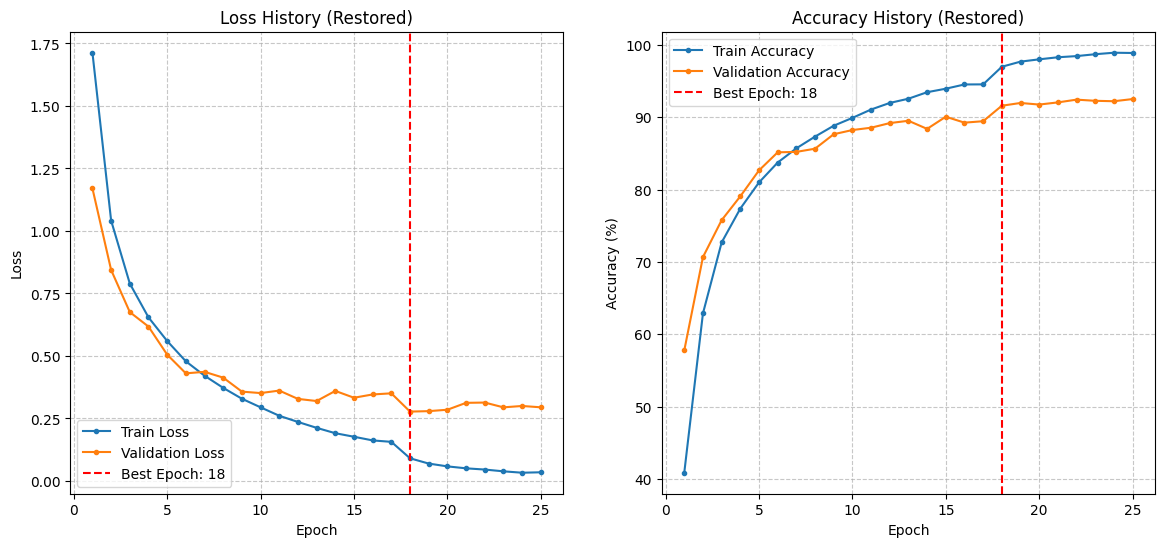

In [38]:
if os.path.exists('Res_UCN_Training_Graph.png'):
    print(f"Image Res-UCN Model Graph exists. Restoring from Res_UCN_Record.pt")

    data = torch.load('Res_UCN_Record.pt')

    epochs_list = range(1, len(data['train_losses']) + 1)
    best_epoch = data['best_epoch']

    plt.figure(figsize=(14, 6))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_list, data['train_losses'], label='Train Loss', marker='.')
    plt.plot(epochs_list, data['val_losses'], label='Validation Loss', marker='.')
    plt.axvline(x=best_epoch, color='r', linestyle='--', linewidth=1.5, label=f'Best Epoch: {best_epoch}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.title('Loss History (Restored)')

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_list, data['train_acc'], label='Train Accuracy', marker='.')
    plt.plot(epochs_list, data['val_acc'], label='Validation Accuracy', marker='.')
    plt.axvline(x=best_epoch, color='r', linestyle='--', linewidth=1.5, label=f'Best Epoch: {best_epoch}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.title('Accuracy History (Restored)')

    plt.show()

else:
    if len(train_losses) == 0 and os.path.exists('Res_UCN_Record.pt'):
        print("Training skipped. Loading data from Res_UCN_Record.pt for plotting...")
        data = torch.load('Res_UCN_Record.pt')
        train_losses = data['train_losses']
        val_losses = data['val_losses']
        train_accuracies = data['train_acc']
        val_accuracies = data['val_acc']

    if len(train_losses) > 0:
        epochs_ran = len(train_losses)
        epochs_list = range(1, epochs_ran + 1)

        # Identify the best epoch
        best_epoch = val_losses.index(min(val_losses)) + 1
        best_val_loss = min(val_losses)

        plt.figure(figsize=(14, 6))

        # Plot Loss
        plt.subplot(1, 2, 1)
        plt.plot(epochs_list, train_losses, label='Train Loss', marker='.')
        plt.plot(epochs_list, val_losses, label='Validation Loss', marker='.')
        # Draw Vertical Line
        plt.axvline(x=best_epoch, color='r', linestyle='--', linewidth=1.5, label=f'Best Epoch: {best_epoch}')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.title('Loss over Epochs')

        # Plot Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(epochs_list, train_accuracies, label='Train Accuracy', marker='.')
        plt.plot(epochs_list, val_accuracies, label='Validation Accuracy', marker='.')
        # Draw Vertical Line
        plt.axvline(x=best_epoch, color='r', linestyle='--', linewidth=1.5, label=f'Best Epoch: {best_epoch}')
        plt.axhline(y=89.9, color='blue', linestyle='--', linewidth=1.5, label='Baseline (89.9%)')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy (%)')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.title('Accuracy over Epochs')

        plt.tight_layout()
        plt.savefig('Res_UCN_Training_Graph.png')
        plt.show()

        print(f"Plot saved with vertical line at epoch {best_epoch}")
    else:
        print("No training data found. Cannot plot.")

# **Res-UCN Total Parameter**

In [39]:
from torch.nn import Parameter

par = 0
for param in model.parameters():
    par += param.numel()
print(f"Number of parameters: {par:,}")

Number of parameters: 3,447,630


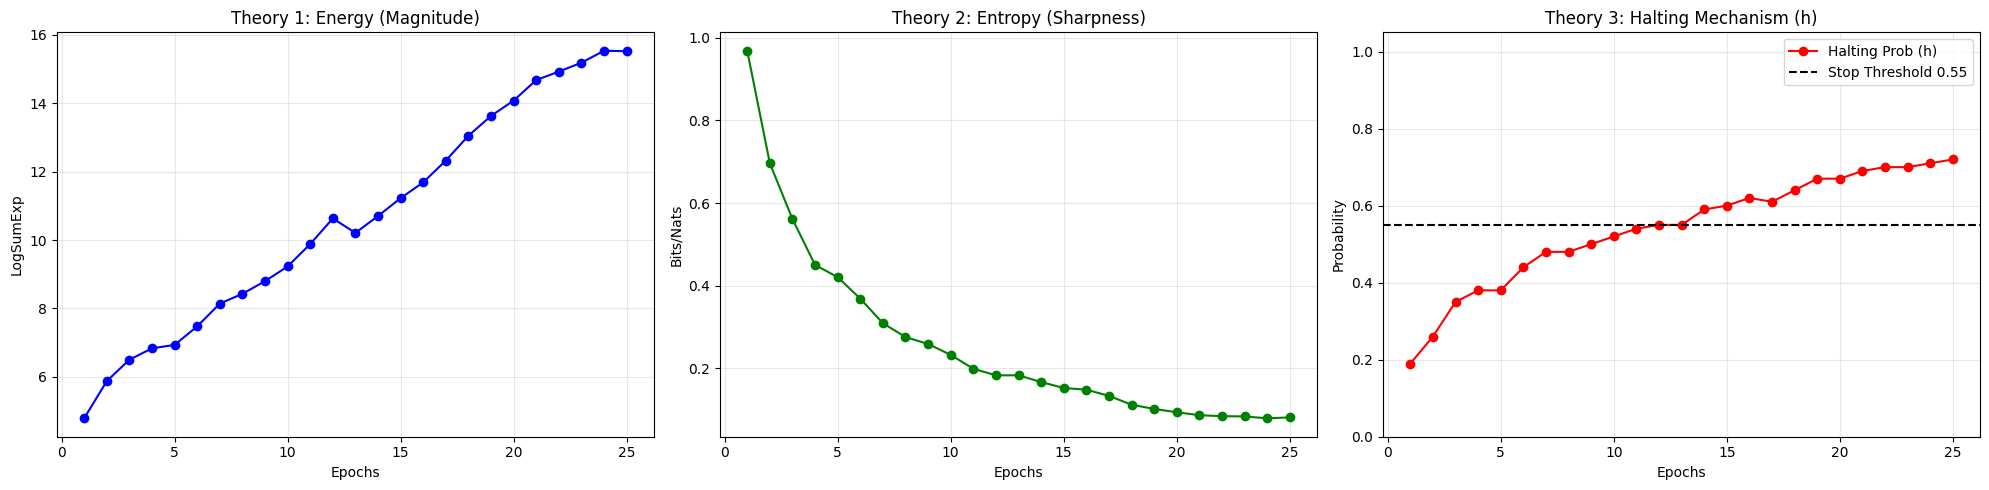

In [40]:
if os.path.exists('Res_UCN_ES_Record.pt'):
    # We add weights_only=False because the file contains lists/numpy scalars, not just model weights
    data = torch.load('Res_UCN_ES_Record.pt', weights_only=False)

    energies = data['early_stopping_energy']
    entropies = data['early_stopping_entropy']
    h_values = data['early_stopping_h']
    threshold = 0.55

    epochs = range(1, len(energies) + 1)

    # Create the 3 plots
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))

    # 1. Energy
    ax1.plot(epochs, energies, 'b-o', label='Energy')
    ax1.set_title('Theory 1: Energy (Magnitude)')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('LogSumExp')
    ax1.grid(True, alpha=0.3)

    # 2. Entropy
    ax2.plot(epochs, entropies, 'g-o', label='Entropy')
    ax2.set_title('Theory 2: Entropy (Sharpness)')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Bits/Nats')
    ax2.grid(True, alpha=0.3)

    # 3. H-Value (The Halting Probability)
    ax3.plot(epochs, h_values, 'r-o', label='Halting Prob (h)')
    ax3.axhline(y=threshold, color='k', linestyle='--', label=f'Stop Threshold {threshold}')
    ax3.set_title('Theory 3: Halting Mechanism (h)')
    ax3.set_xlabel('Epochs')
    ax3.set_ylabel('Probability')
    ax3.set_ylim(0, 1.05)
    ax3.grid(True, alpha=0.3)
    ax3.legend()

    plt.tight_layout()
    plt.show()
else:
    print("File 'Res_UCN_Record.pt' not found. Please run the saving block first.")